# code_069 · Spatial and graph-aware evaluation

**Book:** section 14.3. A self-contained deployment-matched validation laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_14_GUIDE.md), [run evidence](../CHAPTER_14_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_069).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
START=time.perf_counter();SEED=1469;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0'}
CPU: Darwin arm64 seed: 1469


<a id="spatial"></a>
## A held region changes the distance to observed examples

Generate 25 by 25 coordinates on [0,1]^2 and y=sin(3*pi*x)*cos(2*pi*y-coordinate)+Gaussian(.05). A fixed five-neighbor regressor fits either a shuffled 80% of locations (interpolation among known surroundings) or all locations x<.8 (predict the right-hand connected block). Different assessment sets answer different tasks; there is no claim that their score difference estimates the causal effect of blocking. Coordinates are admitted at prediction, no target enters a feature, and no hyperparameter is selected on either assessment set.


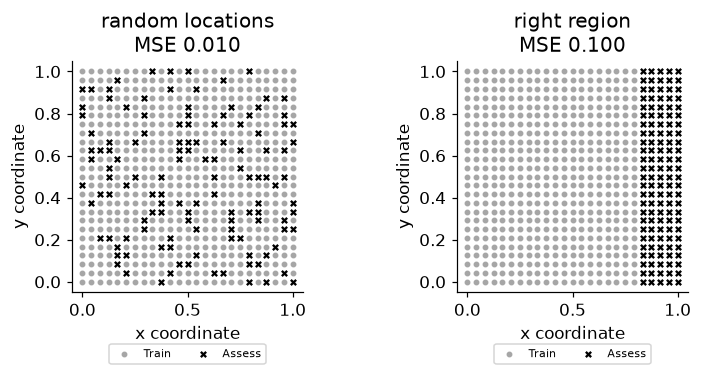

In [2]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error
u,v=np.meshgrid(np.linspace(0,1,25),np.linspace(0,1,25));coords=np.column_stack([u.ravel(),v.ravel()]);y=np.sin(3*np.pi*coords[:,0])*np.cos(2*np.pi*coords[:,1])+rng.normal(0,.05,len(coords));order=rng.permutation(len(coords));random_train=order[:500];random_test=order[500:];block_train=np.flatnonzero(coords[:,0]<.8);block_test=np.flatnonzero(coords[:,0]>=.8);spatial=[]
for name,tr,te in [('random_locations',random_train,random_test),('right_region',block_train,block_test)]:
 assert not set(tr)&set(te);p=KNeighborsRegressor(5).fit(coords[tr],y[tr]).predict(coords[te]);spatial.append({'protocol':name,'train_locations':len(tr),'assessment_locations':len(te),'mse':float(mean_squared_error(y[te],p))})
RESULTS['spatial']=spatial
fig,axes=plt.subplots(1,2,figsize=(7,3.3))
for ax,tr,te,row in zip(axes,[random_train,block_train],[random_test,block_test],spatial):
 ax.scatter(*coords[tr].T,s=8,color='.65',label='Train');ax.scatter(*coords[te].T,s=12,marker='x',color='black',label='Assess');ax.set(title=f"{row['protocol'].replace('_',' ')}\nMSE {row['mse']:.3f}",xlabel='x coordinate',ylabel='y coordinate',aspect='equal');ax.legend(fontsize=7,loc='upper center',bbox_to_anchor=(.5,-.2),ncol=2)
plt.show()


<a id="graph"></a>
## Known graph nodes and new graphs expose different information

Thirty independent 12-node path graphs have scalar node feature z and neighborhood mean nz computed from both endpoint covariates on the full graph, using no labels. Response=.4*z+.8*nz+.35*graph intercept+Gaussian(.1). For the first 24 graphs, hold nodes with index divisible by four, while all their covariates and edges are legitimately known before training (transductive input protocol). Separately train on all nodes of those 24 graphs and assess six previously unseen graphs (inductive graph protocol). At a new graph request its complete topology and node covariates are assumed available. Both use fixed OLS, with either z alone or [z,nz]. Neither is a neural network or a label propagation procedure. Report equal graph-weighted MSE; node counts are equal within each assessment here.


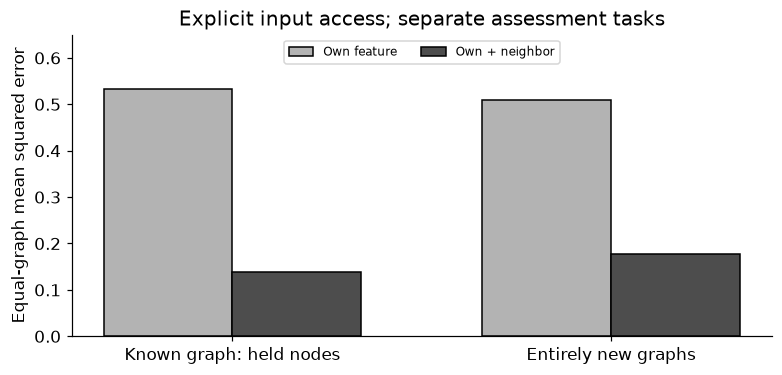

In [3]:
g=np.repeat(np.arange(30),12);z=rng.normal(size=(30,12));nz=np.empty_like(z)
for j in range(12):nz[:,j]=z[:,[k for k in [j-1,j+1] if 0<=k<12]].mean(axis=1)
A=np.zeros((12,12))
for j in range(11):A[j,j+1]=A[j+1,j]=1
np.testing.assert_allclose(nz,(A@z.T/A.sum(axis=1)[:,None]).T)
intercept=rng.normal(size=30);y=(.4*z+.8*nz+.35*intercept[:,None]+rng.normal(0,.1,z.shape)).ravel();X=np.column_stack([z.ravel(),nz.ravel()]);node=np.tile(np.arange(12),30);known_train=np.flatnonzero((g<24)&(node%4!=0));known_test=np.flatnonzero((g<24)&(node%4==0));new_train=np.flatnonzero(g<24);new_test=np.flatnonzero(g>=24)
assert set(g[known_test])<=set(g[known_train]);assert not set(g[new_train])&set(g[new_test])
# A feature-only function ignores any later alteration to a target array.
original=X.copy();changed_labels=y+1e6;np.testing.assert_array_equal(original,np.column_stack([z.ravel(),nz.ravel()]))
rows=[]
for protocol,tr,te in [('known_graph_nodes',known_train,known_test),('new_graphs',new_train,new_test)]:
 for dimensions in [1,2]:
  p=LinearRegression().fit(X[tr,:dimensions],y[tr]).predict(X[te,:dimensions]);per_graph=[float(np.mean((p[g[te]==k]-y[te][g[te]==k])**2)) for k in np.unique(g[te])];rows.append({'protocol':protocol,'features':'own' if dimensions==1 else 'own_and_neighbor','train_nodes':len(tr),'assessment_nodes':len(te),'assessment_graphs':len(per_graph),'macro_graph_mse':float(np.mean(per_graph)),'per_graph_mse':per_graph})
RESULTS['graph']=rows;RESULTS['graph_inputs']={'topology':'complete path per request','held_node_covariates':'known before fitting in transductive case','held_labels_used_in_features':False}
fig,ax=plt.subplots(figsize=(7,3.3));positions=np.arange(2)
for j,label in enumerate(['own','own_and_neighbor']):ax.bar(positions+(j-.5)*.34,[r['macro_graph_mse'] for r in rows if r['features']==label],width=.34,color=['.7','.3'][j],edgecolor='black',label={'own':'Own feature','own_and_neighbor':'Own + neighbor'}[label])
ax.set(xticks=positions,xticklabels=['Known graph: held nodes','Entirely new graphs'],ylabel='Equal-graph mean squared error',title='Explicit input access; separate assessment tasks',ylim=(0,.65));ax.legend(fontsize=8,loc='upper center',ncol=2);plt.show()


In [4]:
summary={'example_id':'code_069','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['random interpolation versus held spatial region', 'unseen nodes in known graphs', 'unseen graphs with request-time features', 'label-free neighborhood construction'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["random interpolation versus held spatial region", "unseen nodes in known graphs", "unseen graphs with request-time features", "label-free neighborhood construction"], "elapsed_seconds": 0.291, "example_id": "code_069", "hardware": "Darwin arm64 CPU", "results": {"graph": [{"assessment_graphs": 24, "assessment_nodes": 72, "features": "own", "macro_graph_mse": 0.5323617817755585, "per_graph_mse": [0.19195225887540027, 0.526944617941351, 0.24198444641654762, 0.13692138402035683, 0.2872711270476973, 2.0678587479375516, 0.6284109082620096, 0.9374416771632813, 0.7721223773228867, 1.2676876360178488, 0.36500033903028806, 0.11032738469559324, 0.17863930198535147, 0.05608600129389798, 0.6416692996802209, 0.12102731900866374, 0.33297133251984673, 0.5367622034827776, 0.11778582183935234, 0.32762125508740314, 0.21718838361707302, 2.0596781512116222, 0.3682880446598964, 0.2850427434964843], "protocol": "known_graph_nodes", "train_nodes": 216}, {"as